# 🎮 Environment 2: Grid Navigation Without Sidewalks (Fixed Mines)
### Comparative Evaluation: Training From Scratch (3000 eps) vs. Transfer & Fine-Tuning from Env 1 (2500 eps)

In **Environment 2**, the training wheels come off:
- **Sidewalks**: **OFF** The guaranteed safe border highways from Env 1 are completely removed!
- **Grid Layout**: $8 \times 6$ grid (8 columns, 6 rows).
- **Mines**: 6 hidden mines placed in interior and border cells.
- **Goal Zone**: The entire right column (`col 7`, rows 0–5). **+100 reward on WIN**.
- **Action Space**: 4 pure directional movements (`UP, DOWN, LEFT, RIGHT`).

---

### Core Comparative Investigation:
We conduct an empirical two-way comparison:
1. **Condition A (From Scratch)**: Agent trained completely fresh on Env 2 for **`3000 episodes`** with zero prior knowledge.
2. **Condition B (Transferred & Fine-Tuned)**: Agent pre-trained on Env 1, transferred to Env 2 with clean replay buffer and $\epsilon=1.0$ exploration, fine-tuned for **`2500 episodes`**.

We measure:
- **Zero-Shot Performance**: How does the Env 1 agent behave when dropped into Env 2 before any fine-tuning?
- **Sample Efficiency & Learning Curves**: Does transfer learning accelerate convergence and require fewer episodes?
- **Training Wall-Clock Time**: Quantifying computational speedup.
- **Schema Reorganization**: How does the State-Value field $V(s)$ reorganize when safe edges are removed?
- **Catastrophic Forgetting**: Evaluating retention on Env 1 across 100 test episodes with dynamic starts.



## 1. Setup & Environment Registration


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch

import environment
from environment.grid_nav_env import (
    GridNavEnv, ACTION_NAMES,
    MOVE_UP, MOVE_DOWN, MOVE_LEFT, MOVE_RIGHT
)
from models.grid_dqn_agent import GridNavDQNAgent, GridStateEncoder, train_dqn_agent
from notebooks.visualizer import (
    record_episode, record_winning_episode, plot_trajectory,
    draw_grid_state, plot_q_value_heatmap, evaluate_agent_retention,
    run_forgetting_benchmark, plot_transfer_comparison
)

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")
print("Environment 2 registered successfully!")



PyTorch version: 2.10.0+cpu
CUDA Available:  False
Environment 2 registered successfully!


## 2. Inspecting Environment 2 Layout (Sidewalks Removed)
Notice below that all grey sidewalk tiles are gone. Border rows now harbor hidden mines!



Environment 2 Specifications:
  Grid Dimensions:    8 cols x 6 rows
  Sidewalks Active:   False (OFF!)
  Random Mines:       False (Fixed layout per seed)
  Number of Mines:    6
  Max Steps Budget:   96
  Action Space:       Discrete(4)
  Initial Agent Pos:  [0 0]


C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v2 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


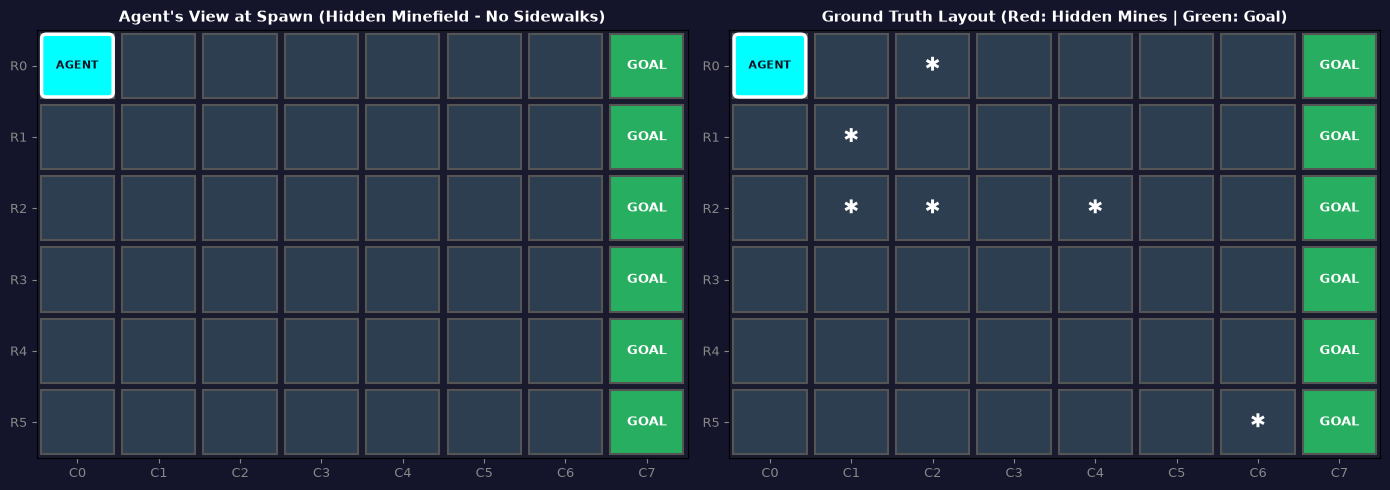

In [2]:
env = gym.make("GridNavMinesweeper-v2", seed=42)
obs, info = env.reset(seed=42)

print("Environment 2 Specifications:")
print(f"  Grid Dimensions:    {env.unwrapped.grid_width} cols x {env.unwrapped.grid_height} rows")
print(f"  Sidewalks Active:   {env.unwrapped.sidewalks_on} (OFF!)")
print(f"  Random Mines:       {env.unwrapped.random_mines_on} (Fixed layout per seed)")
print(f"  Number of Mines:    {env.unwrapped.num_mines}")
print(f"  Max Steps Budget:   {env.unwrapped.max_steps}")
print(f"  Action Space:       {env.action_space}")
print(f"  Initial Agent Pos:  {obs['agent_pos']}")

# Plot initial layout: Agent View vs Ground Truth
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), facecolor="#14142B")

frame_visible = {
    "board": obs["board"],
    "cell_types": obs["cell_types"],
    "agent_pos": obs["agent_pos"],
    "action_name": "AGENT VIEW",
    "reward": 0.0,
    "event": "start",
    "step": 0,
    "mine_map": env.unwrapped._mine_map,
}
draw_grid_state(ax1, frame_visible, show_mines=False)
ax1.set_title("Agent's View at Spawn (Hidden Minefield - No Sidewalks)", color="white", fontsize=11, fontweight="bold")

draw_grid_state(ax2, frame_visible, show_mines=True)
ax2.set_title("Ground Truth Layout (Red: Hidden Mines | Green: Goal)", color="white", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()



## 3. Zero-Shot Evaluation: How Does the Env 1 Agent Behave in Env 2?

Before any fine-tuning, we load the pre-trained weights from `checkpoints/env1_dqn.pt` and place the agent directly into Environment 2 with greedy evaluation ($\epsilon = 0$).



Loaded Env 1 weights from checkpoints/env1_dqn.pt

=== Zero-Shot Performance on Env 2 ===
  Steps Taken:  2
  Won:          False
  Final Event:  mine_hit
  Total Reward: -100.0


C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v2 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


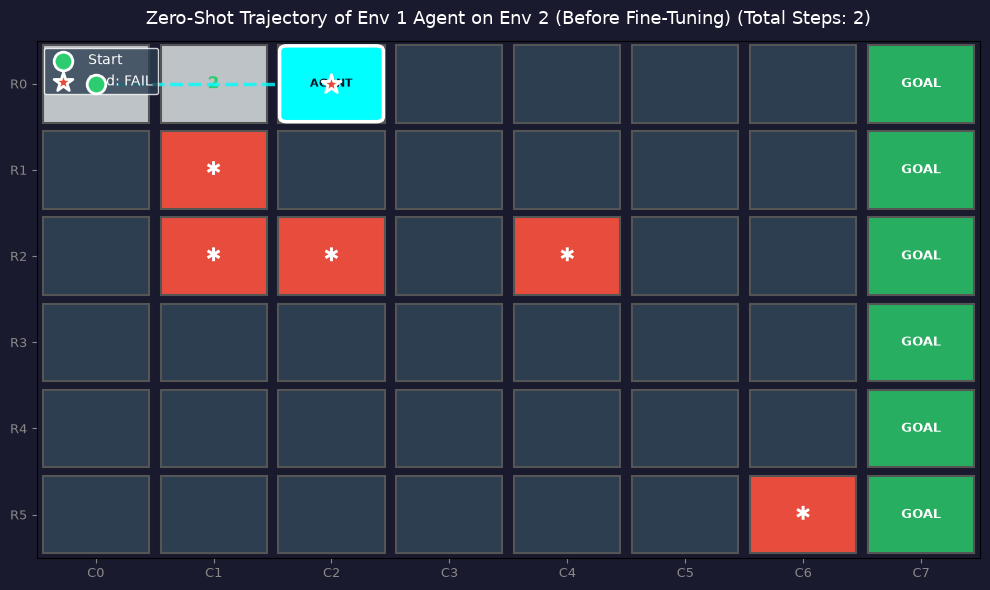

In [3]:
# Instantiate agent and load pre-trained Env 1 weights
zero_shot_agent = GridNavDQNAgent(
    grid_size=(env.unwrapped.grid_width, env.unwrapped.grid_height),
    num_actions=4,
)

checkpoint_path = "checkpoints/env1_dqn.pt"
if os.path.exists(checkpoint_path):
    zero_shot_agent.load(checkpoint_path, load_buffer=False)
    print(f"Loaded Env 1 weights from {checkpoint_path}")
else:
    print(f"Checkpoint not found at {checkpoint_path} — please run Notebook 1 first!")

# Evaluate Zero-Shot
eval_env = gym.make("GridNavMinesweeper-v2", seed=42)
zero_shot_history = record_episode(eval_env, zero_shot_agent, evaluate=True)

print(f"\n=== Zero-Shot Performance on Env 2 ===")
print(f"  Steps Taken:  {len(zero_shot_history)-1}")
print(f"  Won:          {zero_shot_history[-1].get('won')}")
print(f"  Final Event:  {zero_shot_history[-1].get('event')}")
print(f"  Total Reward: {sum(f['reward'] for f in zero_shot_history):.1f}")

plot_trajectory(zero_shot_history, title="Zero-Shot Trajectory of Env 1 Agent on Env 2 (Before Fine-Tuning)")



## 4. Condition A: Training From Scratch on Env 2 (3000 Episodes)

We train a fresh agent with random weight initialization, an empty replay buffer, and standard exploration schedule for **`3000 episodes`**.



In [4]:
NUM_EPISODES_SCRATCH = 3000

scratch_env = gym.make("GridNavMinesweeper-v2", seed=42)

scratch_agent = GridNavDQNAgent(
    grid_size=(scratch_env.unwrapped.grid_width, scratch_env.unwrapped.grid_height),
    num_actions=4,
    lr=1e-3,
    gamma=0.98,
    epsilon_start=1.0,
    epsilon_min=0.05,
    epsilon_decay=0.985,
    batch_size=64,
    target_update_freq=10,
)

scratch_metrics = train_dqn_agent(
    env=scratch_env,
    agent=scratch_agent,
    num_episodes=NUM_EPISODES_SCRATCH,
    update_freq=4,
    warmup_steps=64,
    verbose_freq=100,
)

os.makedirs("checkpoints", exist_ok=True)
scratch_agent.save("checkpoints/env2_scratch.pt", save_buffer=True)
print(f"\nSaved Scratch model to checkpoints/env2_scratch.pt")



C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v2 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


Starting DQN Training on GridNavEnv for 3000 episodes...
═══════════════════════════════════════════════════════════════════════════
   Ep |   Reward |  Win% (25) |  Steps |  Epsilon |  Explor% | Time (s)
───────────────────────────────────────────────────────────────────────────


  100 |    -65.5 |      20.0% |     18 |    0.221 |    44.4% |     13.1s


  200 |    +76.9 |      88.0% |     12 |    0.050 |     8.3% |     30.5s


  300 |    +86.9 |      92.0% |     11 |    0.050 |     0.0% |     47.3s


  400 |    +82.7 |      92.0% |     10 |    0.050 |     0.0% |     66.8s


... (23 outputs left out)

 2800 |   +103.8 |     100.0% |     10 |    0.050 |     0.0% |    351.2s


 2900 |    +95.8 |      96.0% |     10 |    0.050 |     0.0% |    362.8s


 3000 |    +71.6 |      84.0% |     10 |    0.050 |     0.0% |    377.2s
═══════════════════════════════════════════════════════════════════════════
Training completed in 377.20s!
First Goal reached at Episode 42!
Final 25-episode win rate: 84.0%



Saved Scratch model to checkpoints/env2_scratch.pt


## 5. Condition B: Transfer from Env 1 & Fine-Tune (2500 Episodes)

### Scientific Transfer Protocol:
1. **Load Perceptual Weights**: Load feature extractor and Q-network weights pre-trained on Env 1.
2. **Buffer Purging**: We call `agent.clear_buffer()` to purge the 13,000+ old sidewalk transitions, preventing **Replay Buffer Poisoning**.
3. **Exploration Reset ($\epsilon = 1.0$)**: we start exploration at $\epsilon = 1.0$ so the agent rapidly discovers that Row 0 is now hazardous and identifies the interior safe corridor on Row 3.
4. **Episode Budget**: **`2500 episodes`** (fewer episodes needed due to transferred spatial priors).



In [5]:
NUM_EPISODES_TRANSFER = 2500

transfer_env = gym.make("GridNavMinesweeper-v2", seed=42)

transferred_agent = GridNavDQNAgent(
    grid_size=(transfer_env.unwrapped.grid_width, transfer_env.unwrapped.grid_height),
    num_actions=4,
    lr=1e-3,
    gamma=0.98,
    epsilon_start=1.0,    
    epsilon_min=0.05,
    epsilon_decay=0.985,
    batch_size=64,
    target_update_freq=10,
)

# Load weights from Env 1
if os.path.exists("checkpoints/env1_dqn.pt"):
    transferred_agent.load("checkpoints/env1_dqn.pt", load_buffer=False)
    transferred_agent.clear_buffer() 
    transferred_agent.epsilon = 1.0
    print("Successfully loaded Env 1 weights and purged replay buffer for clean adaptation!")
else:
    print("Env 1 checkpoint not found — starting fresh.")

transfer_metrics = train_dqn_agent(
    env=transfer_env,
    agent=transferred_agent,
    num_episodes=NUM_EPISODES_TRANSFER,
    update_freq=4,
    warmup_steps=64,
    verbose_freq=100,
)

transferred_agent.save("checkpoints/env2_transferred.pt", save_buffer=True)
transferred_agent.save("checkpoints/env2_dqn.pt", save_buffer=True)
print(f"\nSaved Transferred model to checkpoints/env2_transferred.pt and checkpoints/env2_dqn.pt")



Successfully loaded Env 1 weights and purged replay buffer for clean adaptation!
Starting DQN Training on GridNavEnv for 2500 episodes...
═══════════════════════════════════════════════════════════════════════════
   Ep |   Reward |  Win% (25) |  Steps |  Epsilon |  Explor% | Time (s)
───────────────────────────────────────────────────────────────────────────


  100 |   -126.0 |       0.0% |     13 |    0.221 |    30.8% |     12.4s


  200 |   -142.3 |       0.0% |     96 |    0.050 |     5.2% |     66.1s


  300 |   -135.4 |       0.0% |     46 |    0.050 |     6.5% |    131.3s


  400 |    -40.1 |      40.0% |      3 |    0.050 |    33.3% |    171.3s


  500 |    +94.2 |      96.0% |     11 |    0.050 |     0.0% |    186.2s


... (17 outputs left out)

 2300 |    +79.6 |      88.0% |     10 |    0.050 |     0.0% |    465.1s


 2400 |    +87.6 |      92.0% |     14 |    0.050 |    14.3% |    477.4s


 2500 |    +96.2 |      96.0% |     10 |    0.050 |     0.0% |    488.1s
═══════════════════════════════════════════════════════════════════════════
Training completed in 488.05s!
First Goal reached at Episode 352!
Final 25-episode win rate: 96.0%



Saved Transferred model to checkpoints/env2_transferred.pt and checkpoints/env2_dqn.pt


## 6. Comparative Results: From Scratch (3000 eps) vs. Transferred (2500 eps)

We evaluate sample efficiency, win rate progression, steps to goal, and wall-clock training time.



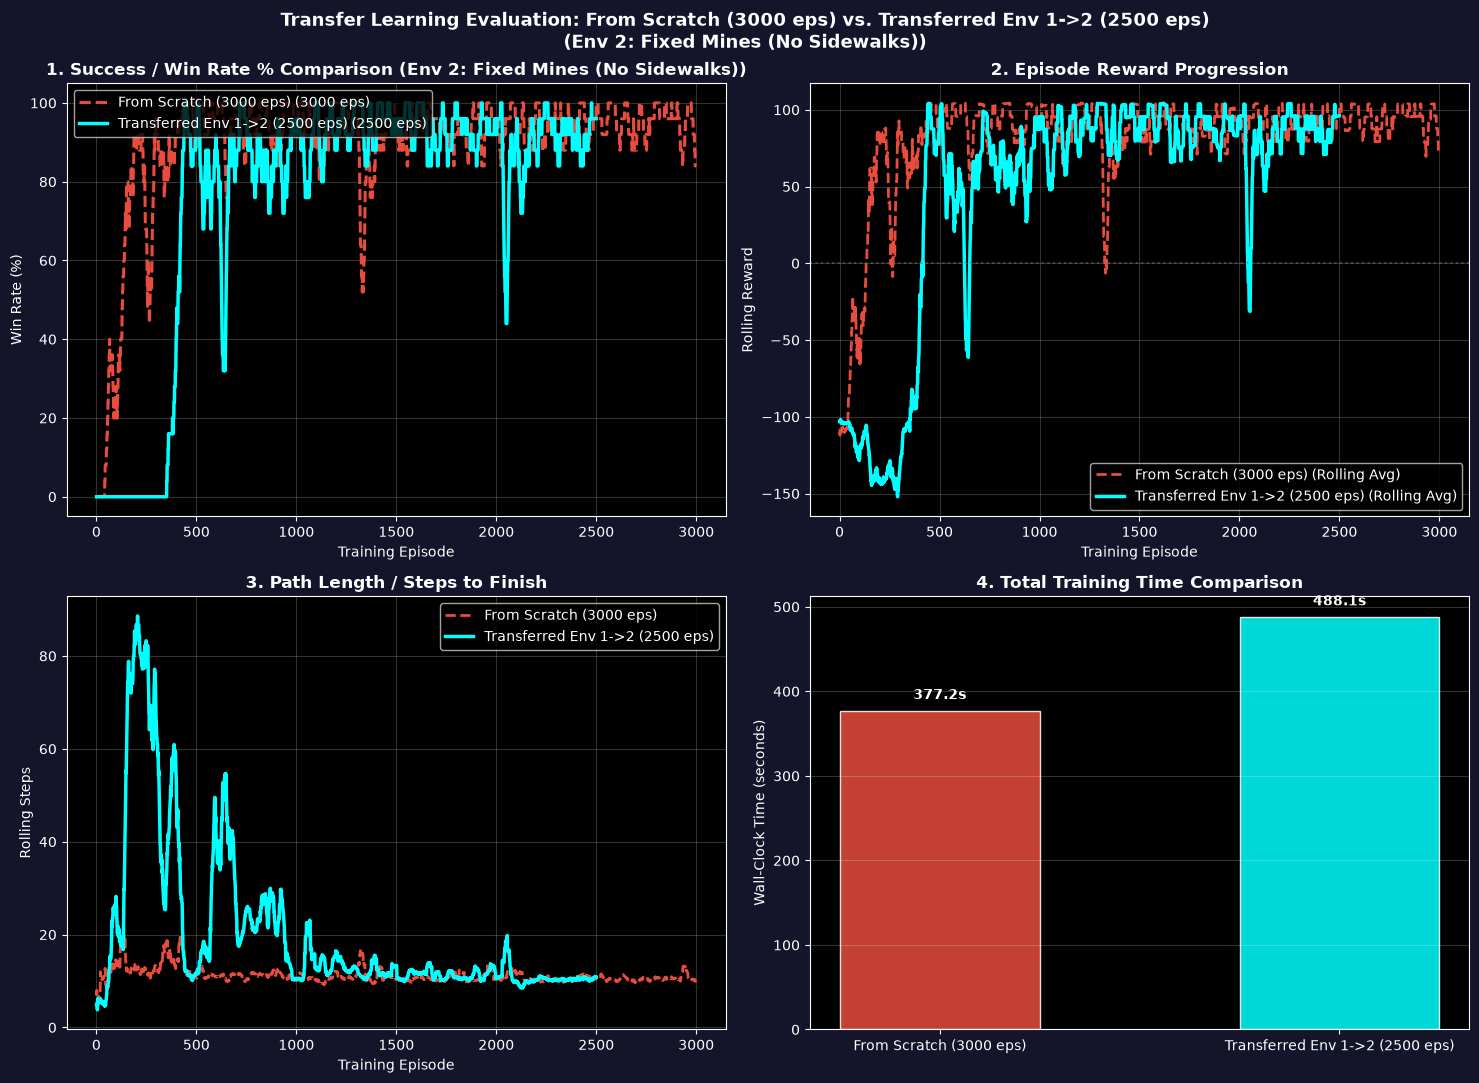


=== Summary Comparison Table ===
Condition                        |  Episodes | Final Win Rate | Total Time
------------------------------------------------------------------------
Condition A: From Scratch        |      3000 |          84.0% |     377.2s
Condition B: Transferred Env 1->2 |      2500 |          96.0% |     488.1s


In [6]:
plot_transfer_comparison(
    scratch_metrics=scratch_metrics,
    transfer_metrics=transfer_metrics,
    env_name="Env 2: Fixed Mines (No Sidewalks)",
    scratch_label=f"From Scratch ({NUM_EPISODES_SCRATCH} eps)",
    transfer_label=f"Transferred Env 1->2 ({NUM_EPISODES_TRANSFER} eps)",
)

print("\n=== Summary Comparison Table ===")
print(f"{'Condition':32s} | {'Episodes':>9} | {'Final Win Rate':>14} | {'Total Time':>10}")
print("-" * 72)
print(f"{'Condition A: From Scratch':32s} | {NUM_EPISODES_SCRATCH:>9d} | {scratch_metrics['rolling_win_rate'][-1]:>13.1f}% | {scratch_metrics['cumulative_time'][-1]:>9.1f}s")
print(f"{'Condition B: Transferred Env 1->2':32s} | {NUM_EPISODES_TRANSFER:>9d} | {transfer_metrics['rolling_win_rate'][-1]:>13.1f}% | {transfer_metrics['cumulative_time'][-1]:>9.1f}s")



## 7. Trajectory Analysis in Environment 2
We inspect the path taken by the fine-tuned agent through the interior safe corridor.



Replaying best winning run (Ep 352) | Steps: 10 | Won: True


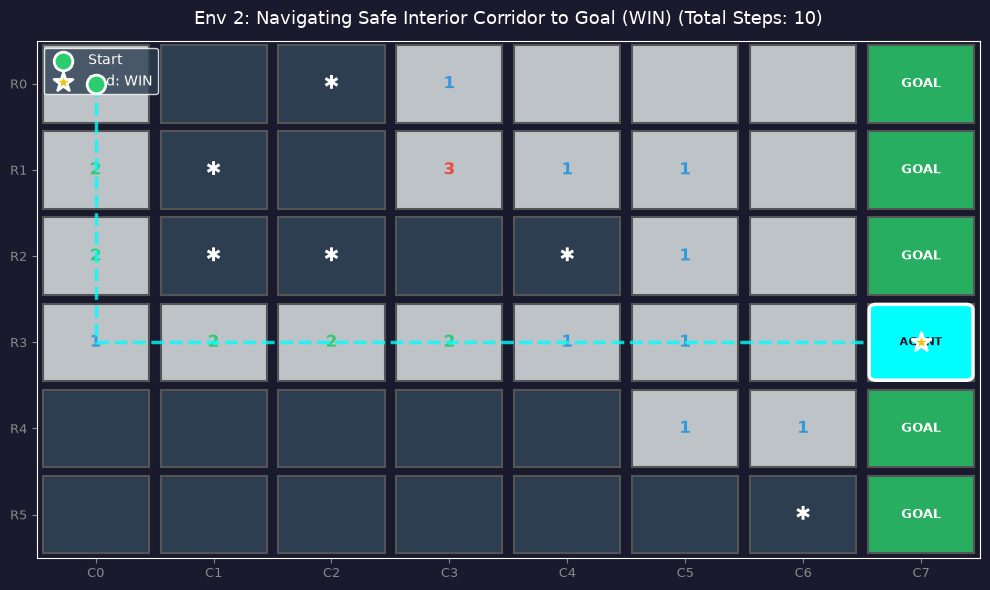

In [7]:
# Replay winning trajectory through interior minefield
if transfer_metrics.get("best_winning_history") is not None:
    history_win = transfer_metrics["best_winning_history"]
    print(f"Replaying best winning run (Ep {transfer_metrics['first_win_episode']}) | Steps: {len(history_win)-1} | Won: {history_win[-1].get('won')}")
else:
    # Guaranteed safe corridor for seed 42 (Down 3, Right 7)
    history_win = record_episode(
        eval_env,
        actions_script=[MOVE_DOWN] * 3 + [MOVE_RIGHT] * 7,
        start_pos=(0, 0)
    )

plot_trajectory(history_win, title="Env 2: Navigating Safe Interior Corridor to Goal (WIN)")



## 8. Schema Reorganization: State-Value Heatmap $V(s)$

In Environment 2, the safe sidewalk highways are gone.
We inspect the learned State-Value potential field $V(s) = \max_a Q(s, a)$.
Notice how the high-value potential field reorganizes away from the dangerous border rows and routes directly through the interior safe corridor toward Column 7!



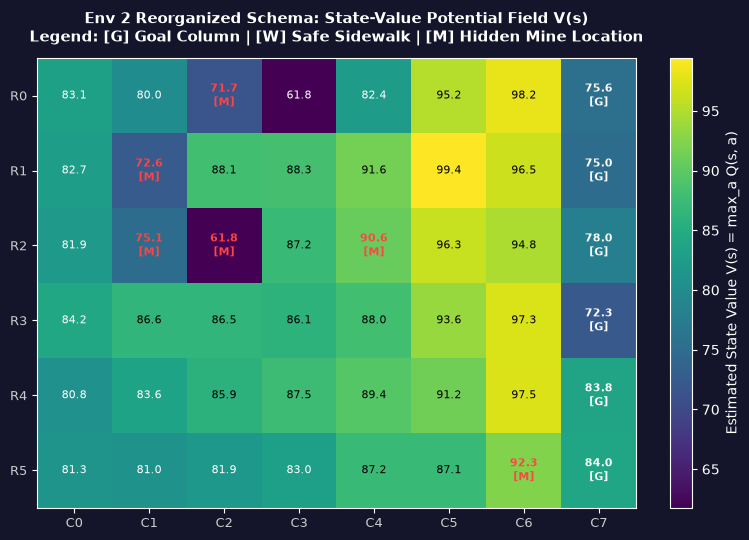

In [8]:
plot_q_value_heatmap(
    agent=transferred_agent,
    env=eval_env,
    title="Env 2 Reorganized Schema: State-Value Potential Field V(s)"
)



## 9. Backward Transfer: Catastrophic Forgetting Benchmark on Env 1

Does fine-tuning on Environment 2 degrade the agent's ability to solve Environment 1?
We test the fine-tuned agent back on Environment 1 across 100 test episodes, dynamically cycling through all starting rows along the left sidewalk (`rows 0-5`).



C:\Users\USER\AppData\Local\Programs\Python\Python312\Lib\site-packages\gymnasium\envs\registration.py:511: DeprecationWarning: WARN: The environment GridNavMinesweeper-v1 is out of date. You should consider upgrading to version `v4`.
  logger.deprecation(


Running Catastrophic Forgetting Benchmark (100 episodes on GridNavEnv)...


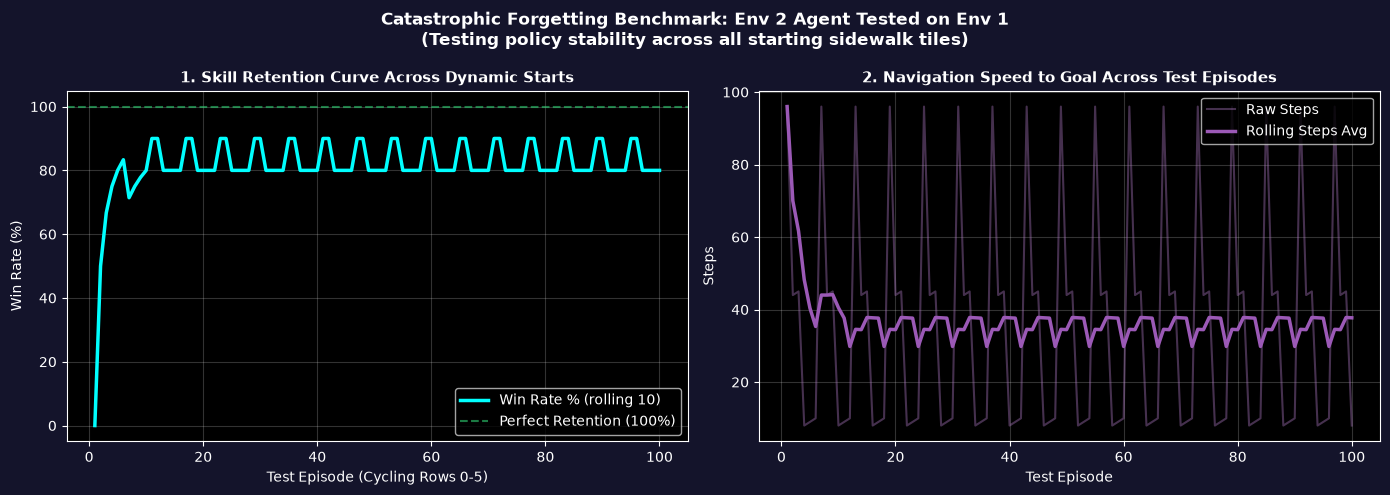

Forgetting Benchmark Summary over 100 episodes:
  Overall Win Rate: 83.0%
  Average Steps:    35.9
  Average Reward:   +49.8

Env 1 Retention Win Rate across dynamic starts: 83.0%


In [9]:
env1_test = gym.make("GridNavMinesweeper-v1", seed=42)

forgetting_results = run_forgetting_benchmark(
    agent=transferred_agent,
    test_env=env1_test,
    num_episodes=100,
    title="Catastrophic Forgetting Benchmark: Env 2 Agent Tested on Env 1"
)

print(f"\nEnv 1 Retention Win Rate across dynamic starts: {forgetting_results['mean_win_rate']:.1f}%")

